# 05 - Threshold, targeting and retention ROI

> **Read this first: the money figures rest on assumptions, and the most important one is unverifiable here.**
> Every value in `src/config/retention_assumptions.yaml` (net interest margin, annual fee, offer cost, **retention success rate**) is an illustrative assumption, not a bank figure.
> In particular the **retention success rate** (the share of contacted would-be churners an offer actually saves) is assumed: **the dataset has no treatment data**, so nobody was offered anything and we cannot observe who responds.
> The model predicts *churn risk*, not *response to an offer*. All amounts are in "units" (no currency is stated).

**Scope.** Test split only (2,000 customers), using the calibrated champion's probabilities, so a probability of 0.3 really means about a 30% chance of churning.
The targeting rules have no fitted parameters (they come from the assumptions), so evaluating them on the test set does not leak.

**Contact capacity (also an assumption).** The retention team can contact at most a fixed share of customers: 10% by default, and 15% is shown alongside.
Within that limit customers are ranked by **expected net benefit** (not raw risk) and anyone whose expected benefit is not positive is skipped, so a cap never forces a loss.
Results under the cap are shown next to the unconstrained cost-based optimum for all three scenarios.
The base scenario is deliberately conservative and the worst scenario is a stress case set near break-even; all inputs are illustrative.

**Definitions** (per customer, in units):
- Annual value = `Balance x net_interest_margin + NumOfProducts x annual_fee_per_product`. A saved customer is credited with one year of value (conservative: no lifetime value).
- Expected net benefit of contacting = `p_churn x success_rate x value - offer_cost`.
- Customers saved = `p_churn x success_rate`; value retained = saved x value; net value = value retained - campaign cost; ROI % = net value / campaign cost.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.models import retention as r

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
COLORS = {"best": "#2a78d6", "base": "#eb6834", "worst": "#1baf7a"}
pd.options.display.float_format = "{:,.2f}".format

reports = r.build_reports()
scored, summary, curves, assumptions = reports["scored"], reports["summary"], reports["curves"], reports["assumptions"]
N = len(scored)

print("ASSUMPTIONS (illustrative, not bank figures; money in units):")
display(pd.DataFrame({s: {"net interest margin": f"{a['net_interest_margin']:.1%}", "annual fee / product": f"{a['annual_fee_per_product']:,} units",
                          "offer cost / customer": f"{a['offer_cost']:,} units", "retention success rate": f"{a['retention_success_rate']:.0%}"}
                      for s, a in assumptions.items()}))
print(f"\nTest customers: {N:,}. Mean predicted risk {scored.risk.mean():.3f} vs actual churn rate {scored.churned_actual.mean():.3f} (calibration sanity check).")

ASSUMPTIONS (illustrative, not bank figures; money in units):


,best,base,worst
net interest margin,3.5%,2.5%,1.5%
annual fee / product,60 units,40 units,20 units
offer cost / customer,40 units,100 units,150 units
retention success rate,30%,15%,8%



Test customers: 2,000. Mean predicted risk 0.201 vs actual churn rate 0.203 (calibration sanity check).


## Customer value and expected net benefit
One year of value per customer, by scenario. Customers with little or no balance are worth little, so a flat offer cost rules them out.

In [2]:
vals = pd.DataFrame({s: scored[f"customer_value_{s}"].describe(percentiles=[0.5, 0.9]) for s in r.SCENARIOS}).loc[["mean", "50%", "90%", "max"]]
display(vals.rename(index={"50%": "median", "90%": "90th percentile"}))
share = pd.DataFrame({s: [(scored[f"expected_net_benefit_{s}"] > 0).mean() * 100] for s in r.SCENARIOS}, index=["% of customers with positive expected net benefit"])
display(share)

,best,base,worst
mean,"2,781.16","1,982.21","1,183.26"
median,"3,476.01","2,480.01","1,483.27"
90th percentile,"5,375.58","3,836.63","2,296.50"
max,"7,504.37","5,357.41","3,210.44"


,best,base,worst
% of customers with positive expected net benefit,61.45,20.20,1.50


## Targeting rules compared
Six ways to pick who to contact: the **unconstrained cost-based rule** (everyone with positive expected net benefit), the same rule under a **10% and a 15% capacity cap**, **risk >= 0.5**, and the **top 10% / top 20% by risk**.
Tables first on the 2,000 test customers, then scaled to 1,000 customers (additive columns multiplied by 0.5; percentages unchanged).
`actual churners reached` counts customers in the targeted group who really churned, as a reality check on the model-based expected figure.

In [3]:
cols = ["rule", "customers_targeted", "pct_targeted", "expected_churners_reached", "actual_churners_reached",
        "customers_saved", "value_retained", "campaign_cost", "net_value", "roi_pct"]
names = {"rule": "rule", "customers_targeted": "targeted", "pct_targeted": "% targeted", "expected_churners_reached": "expected churners reached",
         "actual_churners_reached": "actual churners reached", "customers_saved": "customers saved", "value_retained": "value retained",
         "campaign_cost": "campaign cost", "net_value": "net value", "roi_pct": "ROI %"}
for basis, title in ((f"test_{N}", f"On the {N:,} test customers"), ("per_1000", "Per 1,000 customers")):
    print(f"===== {title} =====")
    for s in r.SCENARIOS:
        t = summary[(summary.scenario == s) & (summary.basis == basis)][cols].copy()
        t["rule"] = t["rule"].map(r.rule_label)
        print(f"-- {s} scenario")
        display(t.rename(columns=names).set_index("rule"))

===== On the 2,000 test customers =====
-- best scenario


,targeted,% targeted,expected churners reached,actual churners reached,customers saved,value retained,campaign cost,net value,ROI %
rule,,,,,,,,,
Unconstrained cost-based (net benefit > 0),"1,229.00",61.45,313.85,319.00,94.15,"391,681.75","49,160.00","342,521.75",696.75
Capacity cap 10% (ranked by net benefit),200.00,10.00,147.24,146.00,44.17,"204,311.79","8,000.00","196,311.79","2,453.90"
Capacity cap 15% (ranked by net benefit),300.00,15.00,184.91,181.00,55.47,"250,383.17","12,000.00","238,383.17","1,986.53"
Risk >= 0.5,242.00,12.10,188.11,180.00,56.43,"190,343.18","9,680.00","180,663.18","1,866.36"
Top 10% by risk,200.00,10.00,165.84,162.00,49.75,"169,396.04","8,000.00","161,396.04","2,017.45"
Top 20% by risk,400.00,20.00,251.50,243.00,75.45,"246,652.70","16,000.00","230,652.70","1,441.58"


-- base scenario


,targeted,% targeted,expected churners reached,actual churners reached,customers saved,value retained,campaign cost,net value,ROI %
rule,,,,,,,,,
Unconstrained cost-based (net benefit > 0),404.00,20.20,210.77,209.00,31.62,"101,200.85","40,400.00","60,800.85",150.50
Capacity cap 10% (ranked by net benefit),200.00,10.00,147.24,146.00,22.09,"72,872.52","20,000.00","52,872.52",264.36
Capacity cap 15% (ranked by net benefit),300.00,15.00,184.91,181.00,27.74,"89,308.52","30,000.00","59,308.52",197.70
Risk >= 0.5,242.00,12.10,188.11,180.00,28.22,"67,850.15","24,200.00","43,650.15",180.37
Top 10% by risk,200.00,10.00,165.84,162.00,24.88,"60,379.72","20,000.00","40,379.72",201.90
Top 20% by risk,400.00,20.00,251.50,243.00,37.72,"87,927.26","40,000.00","47,927.26",119.82


-- worst scenario


...

,targeted,% targeted,expected churners reached,actual churners reached,customers saved,value retained,campaign cost,net value,ROI %
rule,,,,,,,,,
Unconstrained cost-based (net benefit > 0),614.50,61.45,156.92,159.50,47.08,"195,840.88","24,580.00","171,260.88",696.75
Capacity cap 10% (ranked by net benefit),100.00,10.00,73.62,73.00,22.09,"102,155.89","4,000.00","98,155.89","2,453.90"
Capacity cap 15% (ranked by net benefit),150.00,15.00,92.45,90.50,27.74,"125,191.59","6,000.00","119,191.59","1,986.53"
Risk >= 0.5,121.00,12.10,94.06,90.00,28.22,"95,171.59","4,840.00","90,331.59","1,866.36"
Top 10% by risk,100.00,10.00,82.92,81.00,24.88,"84,698.02","4,000.00","80,698.02","2,017.45"
Top 20% by risk,200.00,20.00,125.75,121.50,37.72,"123,326.35","8,000.00","115,326.35","1,441.58"


-- base scenario


,targeted,% targeted,expected churners reached,actual churners reached,customers saved,value retained,campaign cost,net value,ROI %
rule,,,,,,,,,
Unconstrained cost-based (net benefit > 0),202.00,20.20,105.38,104.50,15.81,"50,600.42","20,200.00","30,400.42",150.50
Capacity cap 10% (ranked by net benefit),100.00,10.00,73.62,73.00,11.04,"36,436.26","10,000.00","26,436.26",264.36
Capacity cap 15% (ranked by net benefit),150.00,15.00,92.45,90.50,13.87,"44,654.26","15,000.00","29,654.26",197.70
Risk >= 0.5,121.00,12.10,94.06,90.00,14.11,"33,925.08","12,100.00","21,825.08",180.37
Top 10% by risk,100.00,10.00,82.92,81.00,12.44,"30,189.86","10,000.00","20,189.86",201.90
Top 20% by risk,200.00,20.00,125.75,121.50,18.86,"43,963.63","20,000.00","23,963.63",119.82


-- worst scenario


,targeted,% targeted,expected churners reached,actual churners reached,customers saved,value retained,campaign cost,net value,ROI %
rule,,,,,,,,,
Unconstrained cost-based (net benefit > 0),15.00,1.50,13.80,14.00,1.10,"2,561.01","2,250.00",311.01,13.82
Capacity cap 10% (ranked by net benefit),15.00,1.50,13.80,14.00,1.10,"2,561.01","2,250.00",311.01,13.82
Capacity cap 15% (ranked by net benefit),15.00,1.50,13.80,14.00,1.10,"2,561.01","2,250.00",311.01,13.82
Risk >= 0.5,121.00,12.10,94.06,90.00,7.52,"10,807.66","18,150.00","-7,342.34",-40.45
Top 10% by risk,100.00,10.00,82.92,81.00,6.63,"9,616.38","15,000.00","-5,383.62",-35.89
Top 20% by risk,200.00,20.00,125.75,121.50,10.06,"14,007.51","30,000.00","-15,992.49",-53.31


**How to read the comparison.** Net value (value retained minus campaign cost) is what the bank keeps; ROI % is net value per unit spent.
They answer different questions: narrower campaigns (top 10%) can show a higher ROI % because they only contact the very likeliest churners, but they leave net value on the table.
The cost-based rule is built to maximise net value, so it contacts every customer whose expected benefit is positive.

## With a capacity limit
The unconstrained optimum may ask the team to contact far more customers than it can handle. Here the team is limited to 10% (default) or 15% of customers, taken in order of expected net benefit.
`% of unconstrained net value` shows how much of the unconstrained optimum the capped campaign keeps. The last row of each block (top 10% by risk) has the same size as the 10% cap but ranks by risk alone, so the gap between them is the value of ranking by net benefit.

In [4]:
default_share, shares = r.load_capacity()
show_rules = ["cost_based", *[r.capacity_rule(s) for s in shares], "top_10pct"]
out_cols = ["customers_targeted", "pct_targeted", "customers_saved", "value_retained", "campaign_cost", "net_value", "roi_pct"]
for basis, title in ((f"test_{N}", f"On the {N:,} test customers"), ("per_1000", "Per 1,000 customers")):
    print(f"===== {title} =====")
    blocks = []
    for s in r.SCENARIOS:
        sub = summary[(summary.scenario == s) & (summary.basis == basis)].set_index("rule")
        free = sub.loc["cost_based", "net_value"]
        t = sub.loc[show_rules, out_cols].copy()
        t["% of unconstrained net value"] = 100 * t["net_value"] / free if free > 0 else np.nan
        t.index = pd.MultiIndex.from_product([[s], [r.rule_label(x) for x in show_rules]], names=["scenario", "rule"])
        blocks.append(t.rename(columns={"customers_targeted": "targeted", "pct_targeted": "% targeted", "customers_saved": "customers saved",
                                        "value_retained": "value retained", "campaign_cost": "campaign cost", "net_value": "net value", "roi_pct": "ROI %"}))
    display(pd.concat(blocks))

===== On the 2,000 test customers =====


targeted  % targeted  \
scenario rule                                                               
best     Unconstrained cost-based (net benefit > 0)  1,229.00       61.45   
         Capacity cap 10% (ranked by net benefit)      200.00       10.00   
         Capacity cap 15% (ranked by net benefit)      300.00       15.00   
         Top 10% by risk                               200.00       10.00   
base     Unconstrained cost-based (net benefit > 0)    404.00       20.20   
         Capacity cap 10% (ranked by net benefit)      200.00       10.00   
         Capacity cap 15% (ranked by net benefit)      300.00       15.00   
         Top 10% by risk                               200.00       10.00   
worst    Unconstrained cost-based (net benefit > 0)     30.00        1.50   
         Capacity cap 10% (ranked by net benefit)       30.00        1.50   
         Capacity cap 15% (ranked by net benefit)       30.00        1.50   
         Top 10% by risk                               200.00       10.00   

                                                     customers saved  \
scenario rule                                                          
best     Unconstrained cost-based (net benefit > 0)            94.15   
         Capacity cap 10% (ranked by net benefit)              44.17   
         Capacity cap 15% (ranked by net benefit)              55.47   
         Top 10% by risk                                       49.75   
base     Unconstrained cost-based (net benefit > 0)            31.62   
         Capacity cap 10% (ranked by net benefit)              22.09   
         Capacity cap 15% (ranked by net benefit)              27.74   
         Top 10% by risk                                       24.88   
worst    Unconstrained cost-based (net benefit > 0)             2.21   
         Capacity cap 10% (ranked by net benefit)               2.21   
         Capacity cap 15% (ranked by net benefit)               2.21   
         Top 10% by risk                                       13.27   

                                                     value retained  \
scenario rule                                                         
best     Unconstrained cost-based (net benefit > 0)      391,681.75   
         Capacity cap 10% (ranked by net benefit)        204,311.79   
         Capacity cap 15% (ranked by net benefit)        250,383.17   
         Top 10% by risk                                 169,396.04   
base     Unconstrained cost-based (net benefit > 0)      101,200.85   
         Capacity cap 10% (ranked by net benefit)         72,872.52   
         Capacity cap 15% (ranked by net benefit)         89,308.52   
         Top 10% by risk                                  60,379.72   
worst    Unconstrained cost-based (net benefit > 0)        5,122.01   
         Capacity cap 10% (ranked by net benefit)          5,122.01   
         Capacity cap 15% (ranked by net benefit)          5,122.01   
         Top 10% by risk                                  19,232.75   

                                                     campaign cost  net value  \
scenario rule                                                                   
best     Unconstrained cost-based (net benefit > 0)      49,160.00 342,521.75   
         Capacity cap 10% (ranked by net benefit)         8,000.00 196,311.79   
         Capacity cap 15% (ranked by net benefit)        12,000.00 238,383.17   
         Top 10% by risk                                  8,000.00 161,396.04   
base     Unconstrained cost-based (net benefit > 0)      40,400.00  60,800.85   
         Capacity cap 10% (ranked by net benefit)        20,000.00  52,872.52   
         Capacity cap 15% (ranked by net benefit)        30,000.00  59,308.52   
         Top 10% by risk                                 20,000.00  40,379.72   
worst    Unconstrained cost-based (net benefit > 0)       4,500.00     622.01   
         Capacity cap 10% (ranked by net benefit)         4,500.00     622.01  

===== Per 1,000 customers =====


targeted  % targeted  \
scenario rule                                                               
best     Unconstrained cost-based (net benefit > 0)    614.50       61.45   
         Capacity cap 10% (ranked by net benefit)      100.00       10.00   
         Capacity cap 15% (ranked by net benefit)      150.00       15.00   
         Top 10% by risk                               100.00       10.00   
base     Unconstrained cost-based (net benefit > 0)    202.00       20.20   
         Capacity cap 10% (ranked by net benefit)      100.00       10.00   
         Capacity cap 15% (ranked by net benefit)      150.00       15.00   
         Top 10% by risk                               100.00       10.00   
worst    Unconstrained cost-based (net benefit > 0)     15.00        1.50   
         Capacity cap 10% (ranked by net benefit)       15.00        1.50   
         Capacity cap 15% (ranked by net benefit)       15.00        1.50   
         Top 10% by risk                               100.00       10.00   

                                                     customers saved  \
scenario rule                                                          
best     Unconstrained cost-based (net benefit > 0)            47.08   
         Capacity cap 10% (ranked by net benefit)              22.09   
         Capacity cap 15% (ranked by net benefit)              27.74   
         Top 10% by risk                                       24.88   
base     Unconstrained cost-based (net benefit > 0)            15.81   
         Capacity cap 10% (ranked by net benefit)              11.04   
         Capacity cap 15% (ranked by net benefit)              13.87   
         Top 10% by risk                                       12.44   
worst    Unconstrained cost-based (net benefit > 0)             1.10   
         Capacity cap 10% (ranked by net benefit)               1.10   
         Capacity cap 15% (ranked by net benefit)               1.10   
         Top 10% by risk                                        6.63   

                                                     value retained  \
scenario rule                                                         
best     Unconstrained cost-based (net benefit > 0)      195,840.88   
         Capacity cap 10% (ranked by net benefit)        102,155.89   
         Capacity cap 15% (ranked by net benefit)        125,191.59   
         Top 10% by risk                                  84,698.02   
base     Unconstrained cost-based (net benefit > 0)       50,600.42   
         Capacity cap 10% (ranked by net benefit)         36,436.26   
         Capacity cap 15% (ranked by net benefit)         44,654.26   
         Top 10% by risk                                  30,189.86   
worst    Unconstrained cost-based (net benefit > 0)        2,561.01   
         Capacity cap 10% (ranked by net benefit)          2,561.01   
         Capacity cap 15% (ranked by net benefit)          2,561.01   
         Top 10% by risk                                   9,616.38   

                                                     campaign cost  net value  \
scenario rule                                                                   
best     Unconstrained cost-based (net benefit > 0)      24,580.00 171,260.88   
         Capacity cap 10% (ranked by net benefit)         4,000.00  98,155.89   
         Capacity cap 15% (ranked by net benefit)         6,000.00 119,191.59   
         Top 10% by risk                                  4,000.00  80,698.02   
base     Unconstrained cost-based (net benefit > 0)      20,200.00  30,400.42   
         Capacity cap 10% (ranked by net benefit)        10,000.00  26,436.26   
         Capacity cap 15% (ranked by net benefit)        15,000.00  29,654.26   
         Top 10% by risk                                 10,000.00  20,189.86   
worst    Unconstrained cost-based (net benefit > 0)       2,250.00     311.01   
         Capacity cap 10% (ranked by net benefit)         2,250.00     311.01  

## Net value versus how many customers are contacted
Customers are contacted in order of expected net benefit (highest first). The curve rises while the next customer is worth more than the offer costs, peaks, and falls once it is not. The dot marks the optimum.

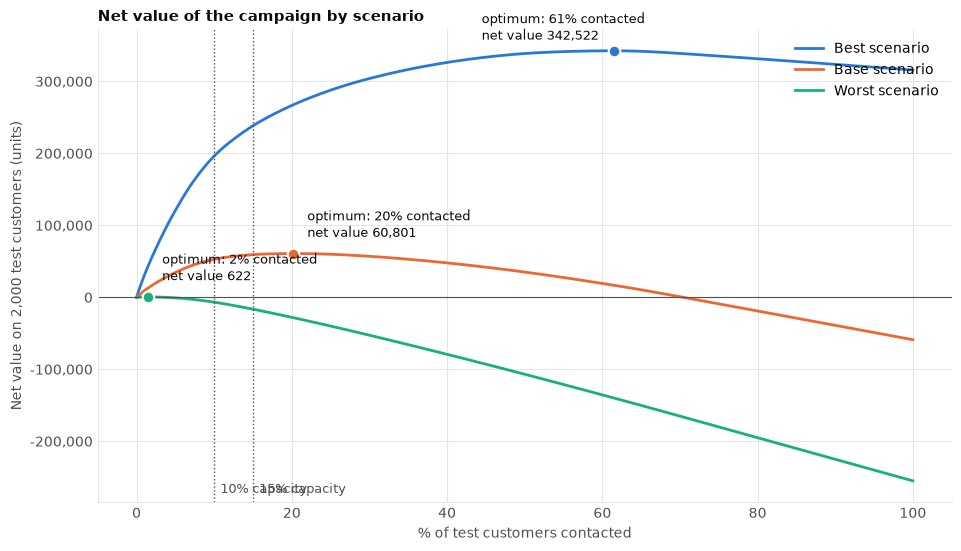

In [5]:
def style(ax, title):
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    ax.set_xlabel("% of test customers contacted", color=MUTED)
    ax.set_ylabel(f"Net value on {N:,} test customers (units)", color=MUTED)
    ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")


fig, ax = plt.subplots(figsize=(9.5, 5.4), constrained_layout=True)
offsets = {"best": (-95, 8), "base": (10, 12), "worst": (10, 12)}
ranked = curves[curves.ranking == "ranked by expected net benefit"]
for s in r.SCENARIOS:
    c = ranked[ranked.scenario == s]
    ax.plot(c.pct_targeted, c.cumulative_net_value, color=COLORS[s], lw=2, label=f"{s.capitalize()} scenario")
    b = c.loc[c.cumulative_net_value.idxmax()]
    ax.scatter([b.pct_targeted], [b.cumulative_net_value], s=70, color=COLORS[s], edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"optimum: {b.pct_targeted:.0f}% contacted\nnet value {b.cumulative_net_value:,.0f}", (b.pct_targeted, b.cumulative_net_value),
                textcoords="offset points", xytext=offsets[s], color=INK, fontsize=9)
ax.axhline(0, color=MUTED, lw=0.8)
for share in r.load_capacity()[1]:
    ax.axvline(100 * share, color=MUTED, lw=1, ls=":")
    ax.text(100 * share + 0.8, ax.get_ylim()[0] + 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0]), f"{share:.0%} capacity", color=MUTED, fontsize=9)
ax.legend(frameon=False, loc="upper right")
style(ax, "Net value of the campaign by scenario")
plt.show()

The same idea for the base scenario, comparing two ways to order customers: by **expected net benefit** (risk and value) versus by **risk alone**.
Ranking by risk alone contacts valuable and worthless customers alike, so it peaks lower. Dots mark each curve's best point; ticks mark the top 10% and top 20% by risk.

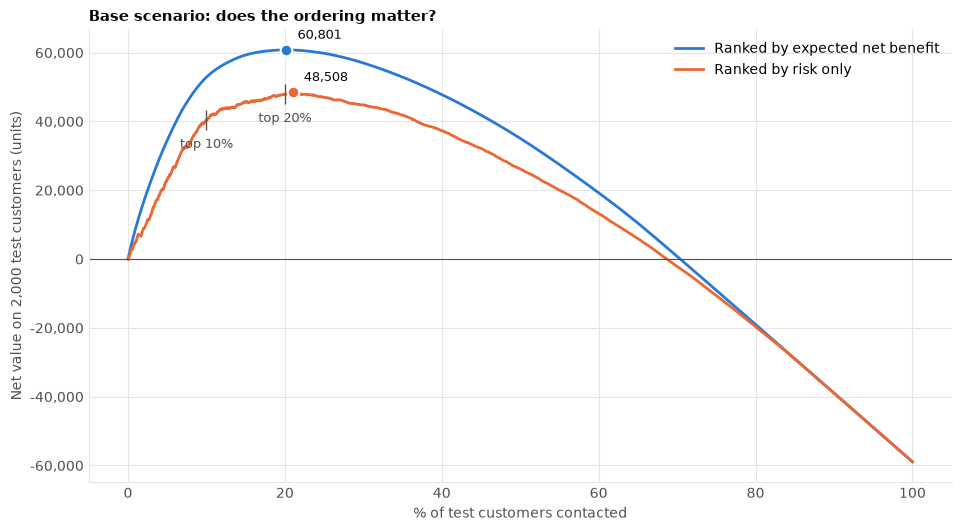

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 5.2), constrained_layout=True)
base = curves[curves.scenario == "base"]
for ranking, color in (("ranked by expected net benefit", "#2a78d6"), ("ranked by risk only", "#eb6834")):
    c = base[base.ranking == ranking]
    ax.plot(c.pct_targeted, c.cumulative_net_value, color=color, lw=2, label=ranking.capitalize())
    b = c.loc[c.cumulative_net_value.idxmax()]
    ax.scatter([b.pct_targeted], [b.cumulative_net_value], s=70, color=color, edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"{b.cumulative_net_value:,.0f}", (b.pct_targeted, b.cumulative_net_value), textcoords="offset points", xytext=(8, 8), color=INK, fontsize=9)
risk_curve = base[base.ranking == "ranked by risk only"].set_index("pct_targeted")["cumulative_net_value"]
for pct in (10, 20):
    ax.plot([pct], [risk_curve.loc[pct]], marker="|", ms=14, color=MUTED)
    ax.annotate(f"top {pct}%", (pct, risk_curve.loc[pct]), textcoords="offset points", xytext=(0, -20), ha="center", color=MUTED, fontsize=9)
ax.axhline(0, color=MUTED, lw=0.8)
ax.legend(frameon=False, loc="upper right")
style(ax, "Base scenario: does the ordering matter?")
plt.show()

## Where the value concentrates
Base scenario under the default capacity cap. `share of campaign net value` is each segment's slice of the total expected net benefit across contacted customers; compare it with its share of customers. The unconstrained optimum's contact count is shown for reference.

In [7]:
cap_col = f"target_{r.capacity_rule(default_share)}_base"
seg = scored.copy()  # scratch copy: the exported frame in `reports` must stay exactly as built by the module
seg["targeted"] = seg[cap_col]
seg["campaign_net_benefit"] = np.where(seg["targeted"], seg["expected_net_benefit_base"], 0.0)
total_net = seg["campaign_net_benefit"].sum()


def segment_table(by, label):
    g = seg.groupby(by)
    t = pd.DataFrame({"customers": g.size(), "% of all customers": 100 * g.size() / N,
                      "contacted (unconstrained)": g["target_cost_based_base"].sum(), "contacted (capped)": g["targeted"].sum(),
                      "% of segment contacted (capped)": 100 * g["targeted"].mean(), "avg risk": g["risk"].mean(),
                      "avg annual value": g["customer_value_base"].mean(),
                      "campaign net value (capped)": g["campaign_net_benefit"].sum()})
    t["share of campaign net value %"] = 100 * t["campaign net value (capped)"] / total_net
    t.index.name = label
    return t


seg["Active member"] = seg["IsActiveMember"].map({1: "Active", 0: "Inactive"})
for by, label in (("Geography", "Geography"), ("Active member", "Active member"), ("NumOfProducts", "Number of products")):
    display(segment_table(by, label))
print(f"Total expected campaign net value (base scenario, {default_share:.0%} capacity cap, {N:,} test customers): {total_net:,.0f} units")

,customers,% of all customers,contacted (unconstrained),contacted (capped),% of segment contacted (capped),avg risk,avg annual value,campaign net value (capped),share of campaign net value %
Geography,,,,,,,,,
France,1012,50.60,124,44,4.35,0.16,"1,575.67","13,125.08",24.82
Germany,499,24.95,218,131,26.25,0.31,"3,065.61","32,982.52",62.38
Spain,489,24.45,62,25,5.11,0.17,"1,718.00","6,764.92",12.79


,customers,% of all customers,contacted (unconstrained),contacted (capped),% of segment contacted (capped),avg risk,avg annual value,campaign net value (capped),share of campaign net value %
Active member,,,,,,,,,
Active,1015,50.75,139,50,4.93,0.14,"1,932.35","9,996.31",18.91
Inactive,985,49.25,265,150,15.23,0.26,"2,033.60","42,876.21",81.09


,customers,% of all customers,contacted (unconstrained),contacted (capped),% of segment contacted (capped),avg risk,avg annual value,campaign net value (capped),share of campaign net value %
Number of products,,,,,,,,,
1,1043,52.15,322,151,14.48,0.27,"2,538.29","37,553.11",71.03
2,891,44.55,49,16,1.80,0.08,"1,356.87","4,245.34",8.03
3,56,2.80,28,28,50.00,0.76,"1,639.90","9,360.27",17.70
4,10,0.50,5,5,50.00,0.92,"1,618.39","1,713.80",3.24


Total expected campaign net value (base scenario, 10% capacity cap, 2,000 test customers): 52,873 units


## Audit: who is selected, by Gender (not a model input)
The champion does not use Gender, but the exported `Gender` column lets the dashboard check how the campaign treats men and women. Same base scenario and 10% capacity cap as above.

In [8]:
g = seg.groupby("Gender")
audit = pd.DataFrame({"customers": g.size(), "% of all customers": 100 * g.size() / N, "avg predicted risk": g["risk"].mean(),
                      "actual churn rate": g["churned_actual"].mean(), "% selected (capped)": 100 * g["targeted"].mean(),
                      "share of campaign net value %": 100 * g["campaign_net_benefit"].sum() / total_net})
display(audit)

,customers,% of all customers,avg predicted risk,actual churn rate,% selected (capped),share of campaign net value %
Gender,,,,,,
Female,901,45.05,0.22,0.26,11.88,53.32
Male,1099,54.95,0.19,0.16,8.46,46.68


## How sensitive is this to the success rate?
Because the success rate is assumed, here is net value as it varies, holding every other base assumption fixed (margin, fee and offer cost at their base values).
The cost-based rule re-selects customers at each success rate; the other rules keep their fixed groups, so they can lose money when the success rate is low.

In [9]:
a = assumptions["base"]
value = r.customer_value(scored["Balance"].to_numpy(), scored["NumOfProducts"].to_numpy(), a["net_interest_margin"], a["annual_fee_per_product"])
p, y = scored["risk"].to_numpy(), scored["churned_actual"].to_numpy()
rows = []
for sr in (0.05, 0.10, 0.20, 0.30, 0.40):
    benefit = r.expected_net_benefit(p, value, sr, a["offer_cost"])
    row = {"success rate": f"{sr:.0%}"}
    for rule in r.rules_for():
        row[r.rule_label(rule)] = r.campaign_summary(r.select_targets(rule, p, benefit), p, value, y, sr, a["offer_cost"])["net_value"]
    rows.append(row)
display(pd.DataFrame(rows).set_index("success rate"))
print("Net value on the 2,000 test customers (units), base margin / fee / offer cost.")

,Unconstrained cost-based (net benefit > 0),Capacity cap 10% (ranked by net benefit),Capacity cap 15% (ranked by net benefit),Risk >= 0.5,Top 10% by risk,Top 20% by risk
success rate,,,,,,
5%,"5,233.86","5,233.86","5,233.86","-1,583.28",126.57,"-10,690.91"
10%,"29,689.65","28,581.68","29,689.65","21,033.44","20,253.14","18,618.18"
20%,"96,507.75","77,163.36","89,078.03","66,266.87","60,506.29","77,236.35"
30%,"175,936.18","125,745.03","148,617.04","111,500.31","100,759.43","135,854.53"
40%,"261,647.84","174,326.71","208,156.05","156,733.74","141,012.58","194,472.71"


Net value on the 2,000 test customers (units), base margin / fee / offer cost.


## Exports for the Tableau dashboard (Stage 8)
Written to `reports/`. No `CustomerId`, `Surname` or `RowNumber`; `test_index` is an anonymous row number within the test set.

In [10]:
paths = r.write_reports(reports)
forbidden = r.FORBIDDEN_COLUMNS
for name, path in paths.items():
    df = pd.read_csv(path)
    assert not (forbidden & set(df.columns)), name
    print(f"{path.relative_to(root)}: {len(df):,} rows x {df.shape[1]} columns")
print()
print("scored_test_customers.csv columns:", list(pd.read_csv(paths['scored_test_customers.csv'], nrows=1).columns))
display(pd.read_csv(paths["scored_test_customers.csv"]).head(3).round(3))

reports\scored_test_customers.csv: 2,000 rows x 32 columns


reports\scenario_summary.csv: 36 rows x 12 columns
reports\net_value_curves.csv: 12,006 rows x 5 columns

scored_test_customers.csv columns: ['test_index', 'risk', 'churned_actual', 'Geography', 'Gender', 'age_band', 'Age', 'NumOfProducts', 'IsActiveMember', 'HasCrCard', 'zero_balance', 'Balance', 'Tenure', 'CreditScore', 'customer_value_best', 'expected_net_benefit_best', 'target_cost_based_best', 'target_capacity_10pct_best', 'target_capacity_15pct_best', 'customer_value_base', 'expected_net_benefit_base', 'target_cost_based_base', 'target_capacity_10pct_base', 'target_capacity_15pct_base', 'customer_value_worst', 'expected_net_benefit_worst', 'target_cost_based_worst', 'target_capacity_10pct_worst', 'target_capacity_15pct_worst', 'target_threshold_0_5', 'target_top_10pct', 'target_top_20pct']


,test_index,risk,churned_actual,Geography,Gender,age_band,Age,NumOfProducts,IsActiveMember,HasCrCard,...,target_capacity_10pct_base,target_capacity_15pct_base,customer_value_worst,expected_net_benefit_worst,target_cost_based_worst,target_capacity_10pct_worst,target_capacity_15pct_worst,target_threshold_0_5,target_top_10pct,target_top_20pct
0,0,0.95,1,France,Female,40-49,42,3,0,1,...,1,1,"2,454.91",36.73,1,1,1,1,1,1
1,1,0.15,0,Spain,Female,40-49,43,1,1,1,...,0,0,"1,902.66",-127.84,0,0,0,0,0,0
2,2,0.88,1,Germany,Female,18-29,29,4,0,1,...,1,1,"1,805.70",-22.82,0,0,0,1,1,1


## Conclusions

**Everything below is conditional on assumed inputs, above all the retention success rate (15% in the base case, 8% in the worst case), which cannot be checked with this data. The base case is deliberately conservative and the worst case is a stress case set near break-even; all inputs are illustrative. Scoring uses the current champion (v2, no Gender).**

**1. Base case under the 10% capacity cap.** If the team can contact only 10% of customers, taken in order of expected net benefit, the campaign nets **52,873 units on the 2,000 test customers (about 26,400 per 1,000)**, an ROI of 264%: 200 customers contacted, about 22 saved, 72,873 retained for 20,000 spent.

| Base scenario, 2,000 test customers | Contacted | Net value | Net per 1,000 | ROI % |
|---|---|---|---|---|
| Unconstrained cost-based optimum | 404 (20.2%) | 60,801 | 30,400 | 150 |
| 15% capacity cap | 300 | 59,309 | 29,654 | 198 |
| **10% capacity cap** | **200** | **52,873** | **26,436** | **264** |
| Top 10% by risk (same size) | 200 | 40,380 | 20,190 | 202 |
| Top 20% by risk | 400 | 47,927 | 23,964 | 120 |
| Risk >= 0.5 | 242 | 43,650 | 21,825 | 180 |

**2. What the cap costs, and why ranking by net benefit matters.** A 10% cap keeps 87% of the unconstrained optimum's net value; a 15% cap keeps 98%, so most of the value is in the first few hundred customers.
Ranking by expected net benefit instead of raw risk adds 31% more net value at the same size (52,873 against 40,380 for the top 10% by risk), because risk-only ranking spends offers on high-risk customers with little balance.
Higher ROI % on the smaller campaigns is just the same money working on fewer, better customers; net value is the number that says how much the bank keeps.

**3. All three scenarios under the cap.**

| | Unconstrained | 10% cap | 15% cap | Top 10% by risk |
|---|---|---|---|---|
| Best | 342,522 (61% contacted) | 196,312 | 238,383 | 161,396 |
| Base | 60,801 (20.2%) | 52,873 | 59,309 | 40,380 |
| Worst | 622 (1.5%) | 622 | 622 | -10,767 |

In the best case the cap binds hard (61% of customers would be worth contacting), yet 10% still captures 57% of the unconstrained value and 15% captures 70%. In the base case it binds mildly. In the worst case it does not bind at all.

**4. The worst case is near break-even, and that is where the net-benefit rule earns its keep.** On the worst inputs only 30 customers (1.5%) are worth contacting; the campaign nets 622 units on 4,500 spent (ROI 14%) and saves about 2 customers.
Every fixed-size risk campaign loses money: top 10% by risk -10,767, risk >= 0.5 -14,685, top 20% -31,985. Because the net-benefit rule only contacts customers who are expected to pay for themselves, its expected net value cannot be negative; the other rules can be.

**5. Where the value concentrates (base case, 10% cap).**
- **Germany:** 25% of customers but 62% of the campaign's net value; 26% of German customers are contacted against about 4-5% of French and Spanish customers (higher risk and higher balances: average annual value about 3,066 against 1,576 in France).
- **Inactive members:** 81% of net value.
- **1-product customers:** 71% of net value from 52% of customers. The 66 customers with 3 or 4 products are 3% of customers but 21% of net value (very high risk, average 0.79, but modest balances).

**6. Audit by Gender (not a model input).** Under the base 10% cap, women are selected at 11.9% against 8.5% for men and carry 53% of the campaign's net value (45% of customers). This follows from higher modelled risk for women (average 0.22 against 0.19) rather than from the model using gender;
in Stage 2 women also churned more often (25.1% against 16.5%). Whether that pattern is acceptable for a retention-offer campaign is a business and compliance judgement; the point of exporting the `Gender` column is that the dashboard can monitor it.

**7. The model's expectations are consistent with what happened.** Under the 10% cap the model expected about 147 churners among the 200 contacted and 146 actually churned; mean predicted risk was 0.201 against an actual rate of 0.2035. This supports the probabilities, but says nothing about how many contacted customers an offer would save.

### Limits you should state when presenting this
- **The success rate is an assumption.** There is no treatment data: no customer was offered anything, so response to an offer is unobserved. Net value is very sensitive to it (base case, unconstrained: 5,234 at a 5% success rate, 29,690 at 10%, 96,508 at 20%, 175,936 at 30%).
  At 5% the fixed-size rules already lose money (top 20% by risk -10,691, risk >= 0.5 -1,583). The right way to replace the assumption is a pilot with a randomly held-out group that receives no offer.
- **All inputs are illustrative placeholders:** margin, fee, offer cost, success rate and the 10% / 15% capacity. The ROI percentages are not forecasts. The worst case was set near break-even on purpose to stress the method.
- **Simplifications.** One year of value per saved customer (no lifetime value, no discounting); the same success rate for every customer regardless of risk or value; a saved customer is one who would otherwise have churned.
- **Single test set of 2,000 customers.** No confidence intervals are shown on these money figures; they carry sampling noise as well as assumption risk.
- **Age** remains a model driver; whether age may be used to choose who receives an offer is a compliance question to settle before acting.